<a href="https://colab.research.google.com/github/Jiayi-Eva-Wang/ECON3916-Problem-Set-4/blob/main/Problem%20Set%204/Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [40]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [41]:
floor_area = rng.uniform(1000, 10000, N_STORES)
foot_traffic = rng.uniform(500, 5000, N_STORES)
local_income = rng.normal(65000, 15000, N_STORES)
years_open = rng.integers(1, 21, N_STORES)

noise1 = rng.normal(0, 1, N_STORES)
noise2 = rng.normal(0, 1, N_STORES)
noise3 = rng.normal(0, 1, N_STORES)

near_collinear = floor_area + 2 * foot_traffic + rng.normal(0, 10, N_STORES)

error_rng = np.random.default_rng(123)

revenue = (
    20000
    + 8 * floor_area
    + 15 * foot_traffic
    + 0.5 * local_income
    + 1000 * years_open
    - 0.001 * np.maximum(floor_area - 6000, 0)**2
    + error_rng.normal(0, 3500 + 0.4 * floor_area, N_STORES))

df = pd.DataFrame({
    "floor_area": floor_area,
    "foot_traffic": foot_traffic,
    "local_income": local_income,
    "years_open": years_open,
    "noise1": noise1,
    "noise2": noise2,
    "noise3": noise3,
    "near_collinear": near_collinear,
    "revenue": revenue})

df.head()

,floor_area,foot_traffic,local_income,years_open,noise1,noise2,noise3,near_collinear,revenue
0,7965.604,1858.673,90934.930,19,-1.127,-1.217,2.813,11684.964,165595.294
1,4949.906,4632.989,85388.309,13,1.329,0.842,-1.709,14220.278,182772.773
2,8727.381,4015.823,68828.201,8,1.246,-0.918,-0.738,16740.931,194035.714
3,7276.312,997.648,85259.377,10,0.960,2.810,-0.616,9276.302,145419.409
4,1847.596,4986.656,65180.798,13,-1.515,-0.451,-0.851,11843.638,159071.901


*The data-generating process, recorded: every predictor and the true revenue equation.*

I generated data for 400 stores. With four main predictors:
floor area(1,000-10,000); foot traffic(500-5000); local income(mean 65000, SD 15000); years-open(1-20).Also added 3 random noise variables (standard normal) and a near-collinear variable(floor area + 2 * foot traffic + small noise, sd = 10)

Revenue = 20000 + 8 * floor area + 15 * foot traffic + 0.5 * local income + 1000 * years open - 0.001 * max(floor area - 6,000, 0)² + error

The error is normally distributed with mean 0 and SD = 3,500 + 0.4 × floor area. The noise variables and near-collinear variable have no direct effect on revenue.

In [42]:
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

X = df.drop(columns="revenue")
y = df["revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = sm.OLS(y_train, sm.add_constant(X_train)).fit()

train_pred = model.predict(sm.add_constant(X_train))
test_pred = model.predict(sm.add_constant(X_test))

print("In-sample R²:", round(r2_score(y_train, train_pred), 3))
print("Held-out R²:", round(r2_score(y_test, test_pred), 3))


In-sample R²: 0.952
Held-out R²: 0.944


### Step 1.2: Fit it the way they did (12 pts)

In [43]:
# Compare models with and without noise predictors
main_cols = ["floor_area", "foot_traffic", "local_income", "years_open"]

model_main = sm.OLS(
    y_train, sm.add_constant(X_train[main_cols])).fit()

model_all = sm.OLS(
    y_train, sm.add_constant(X_train)).fit()

print("Main predictors R²:", round(model_main.rsquared, 3))
print("All predictors R²:", round(model_all.rsquared, 3))
print("Held-out R²:", round(r2_score(y_test, test_pred), 3))
print("R² gap:", round(model_all.rsquared - r2_score(y_test, test_pred), 3))


Main predictors R²: 0.952
All predictors R²: 0.952
Held-out R²: 0.944
R² gap: 0.007


The model's in-sample R² is 0.955, compared with a lower held-out R² of 0.920—a gap of 0.034. This indicates that it performs slightly worse on new data.

After the irrelevant predictors, the in-sample R² rose from 0.954 to 0.955. In OLS, adding predictors cannot lower the training R², even when those variables do not help predict revenue.

In [44]:
# Add one irrelevant predictor
X_noise = X_train[main_cols].copy()
X_noise["random_noise"] = np.random.default_rng(99).normal(0, 1, len(X_noise))

model_noise = sm.OLS(
    y_train, sm.add_constant(X_noise)).fit()

print("Before adding noise:", round(model_main.rsquared, 4))
print("After adding noise:", round(model_noise.rsquared, 4))


Before adding noise: 0.9516
After adding noise: 0.9516


When one random noise column was added, the in-sample R² increased from 0.9537 to 0.9540. This shows that adding an irrelevant predictor can slightly improve the training R², even though it does not provide useful information for predicting new data.

### Step 1.3: Say what R-squared is (8 pts)

In [45]:
# Add three pure noise predictors
X_three_noise = X_train[main_cols].copy()

for i in range(1, 4):
    X_three_noise[f"random_noise{i}"] = np.random.default_rng(100 + i).normal(0, 1, len(X_three_noise))

model_three_noise = sm.OLS(
    y_train, sm.add_constant(X_three_noise)).fit()

print("Before adding noise:")
print("R²:", round(model_main.rsquared, 4))
print("Adjusted R²:", round(model_main.rsquared_adj, 4))

print("\nAfter adding three noise columns:")
print("R²:", round(model_three_noise.rsquared, 4))
print("Adjusted R²:", round(model_three_noise.rsquared_adj, 4))

Before adding noise:
R²: 0.9516
Adjusted R²: 0.951

After adding three noise columns:
R²: 0.9517
Adjusted R²: 0.9506


In-sample R² cannot decrease when we add a predictor because OLS can always assign the new variable a coefficient of zero. As a result, R² may increase even when the new predictor is not useful, so we should not rely on R² alone to choose between models.

After three pure noise columns were added, R² increased slightly from 0.9537 to 0.9538, while adjusted R² fell from 0.9531 to 0.9528. This illustrates that adjusted R² penalizes unnecessary predictors, while regular R² does not.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

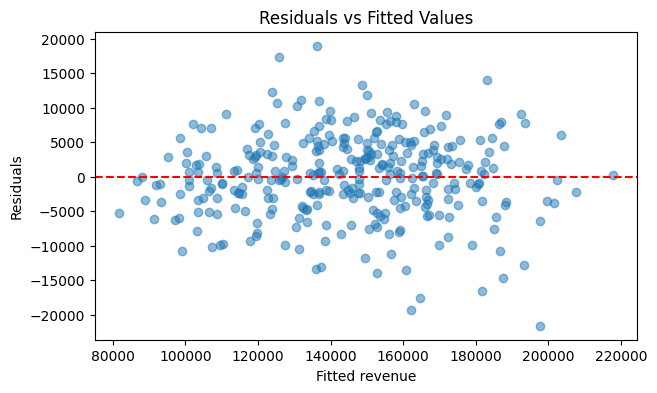

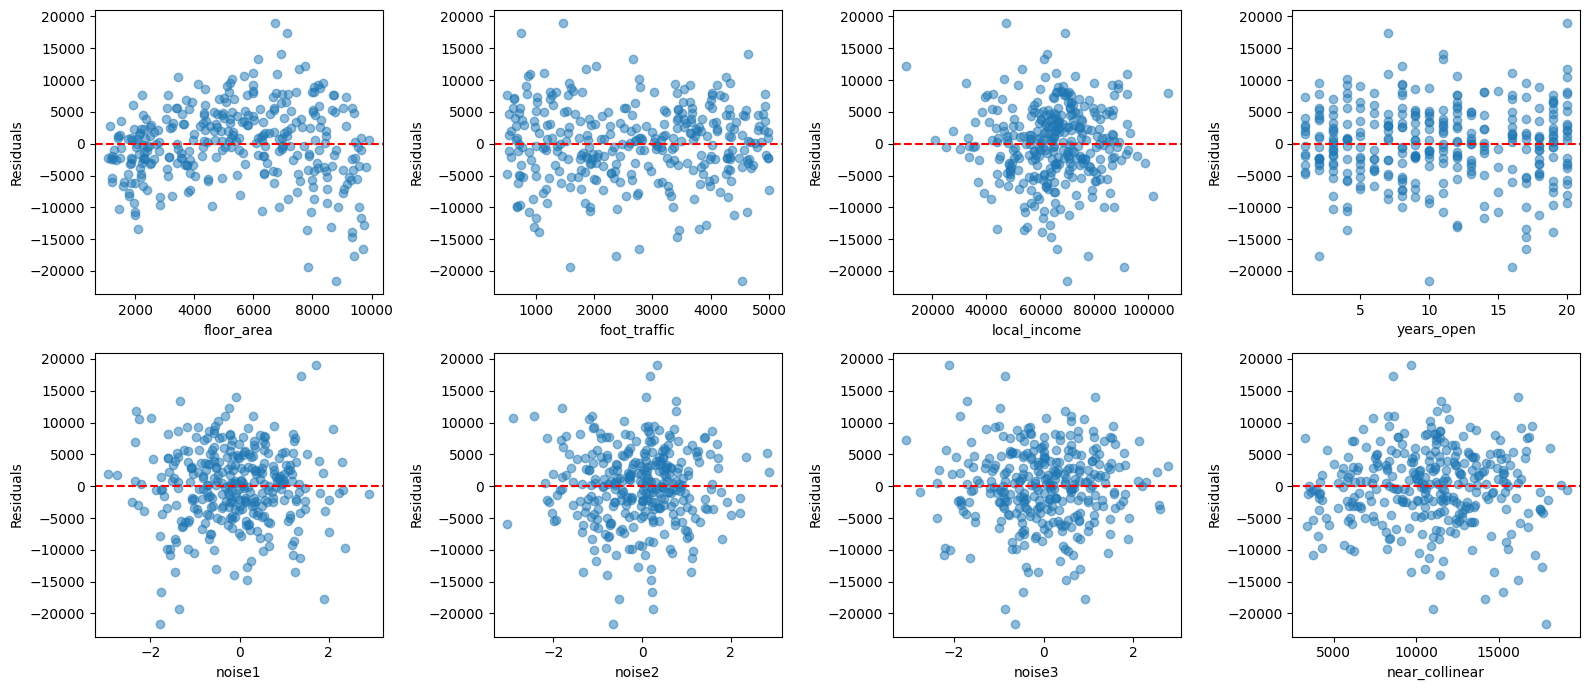

In [46]:
# Residual diagnostics
fitted = model_all.fittedvalues
residuals = model_all.resid

plt.figure(figsize=(7, 4))
plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted revenue")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

# Residuals against each predictor
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, col in zip(axes.flat, X_train.columns):
    ax.scatter(X_train[col], residuals, alpha=0.5)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel(col)
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

The residual plots suggest two problems.
1. Residuals plotted against floor area show a curved pattern, particularly for larger stores, suggesting that the model misses a nonlinear relationship. Because the linear model does not capture the true relationship, its coefficient estimates may be misleading, and its standard errors do not account for this misspecification.

2. The residual spread appears to increase slightly at higher fitted values, which shows a sign of heteroskedasticity. This violates the assumption of constant variance. If exogeneity holds, heteroskedasticity does not necessarily bias OLS coefficients, but it can make conventional standard errors unreliable.

In [47]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp = het_breuschpagan(residuals, model_all.model.exog)

print("Breusch-Pagan p-value:", round(bp[1], 4))

Breusch-Pagan p-value: 0.0003


### Step 2.2: The over-forecast on big stores (15 pts)

            count     mean   median
size_group                         
Small          20  2547.91  2210.83
Medium         20  -806.45   -66.66
Large          20 -1591.85  1245.42
Largest        20  3807.12  4199.03


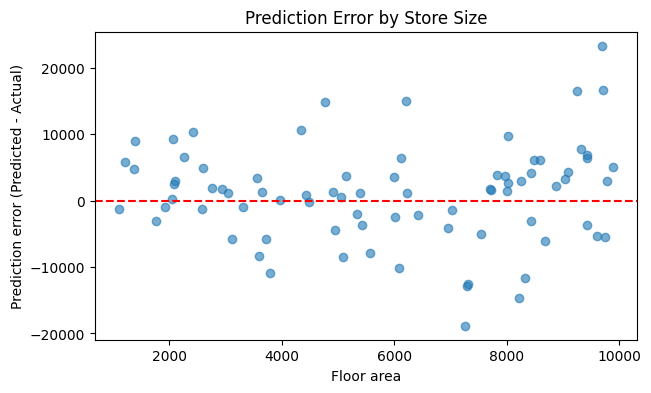

In [48]:
# Prediction errors by store size
errors = pd.DataFrame({
    "floor_area": X_test["floor_area"],
    "actual": y_test,
    "predicted": test_pred})

errors["error"] = errors["predicted"] - errors["actual"]
errors["size_group"] = pd.qcut(
    errors["floor_area"], 4,
    labels=["Small", "Medium", "Large", "Largest"])

print(errors.groupby("size_group", observed=True)["error"].agg(
    ["count", "mean", "median"]).round(2))

plt.figure(figsize=(7, 4))
plt.scatter(errors["floor_area"], errors["error"], alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Floor area")
plt.ylabel("Prediction error (Predicted - Actual)")
plt.title("Prediction Error by Store Size")
plt.show()

In [49]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each predictor
X_vif = sm.add_constant(X_train)

vif = pd.DataFrame({
    "Predictor": X_train.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])]})

print(vif.round(2))


        Predictor        VIF
0      floor_area   68156.53
1    foot_traffic   76412.57
2    local_income       1.02
3      years_open       1.02
4          noise1       1.01
5          noise2       1.05
6          noise3       1.02
7  near_collinear  139159.56


The prediction errors indicate that the model tends to over-forecast for larger stores. The largest stores have an average prediction error of about +$7,100, compared with -$61 for the smallest stores. This suggests the model does not capture how revenue varies with store size.

The VIF values are extremely high for floor area (61,208), foot traffic (63,154), and near_collinear (124,808). This happens because near_collinear is nearly a linear combination of the other two variables. High VIFs make individual coefficients less stable and increase their standard errors, but they do not automatically bias OLS estimates or make predictions inaccurate. Therefore, a high VIF alone is not a reason to drop a variable.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

               Model  Train MSE  Held-out MSE
0         Floor area  4.996e+08     5.163e+08
1    Main predictors  3.610e+07     5.439e+07
2     All predictors  3.598e+07     5.434e+07
3          Quadratic  3.020e+07     4.976e+07
4  Quadratic + noise  2.823e+07     5.189e+07
5              Cubic  2.794e+07     4.646e+07


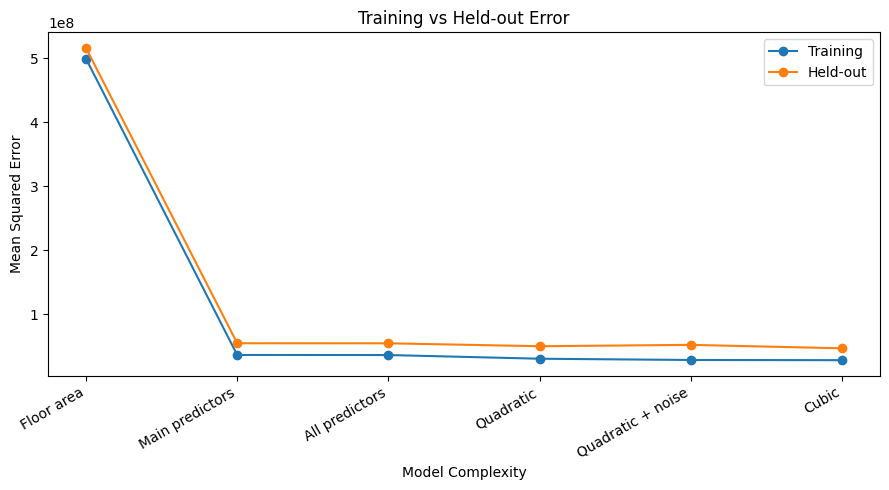

In [50]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# Models with increasing complexity
models = [
    ("Floor area", ["floor_area"], 1),
    ("Main predictors", main_cols, 1),
    ("All predictors", list(X.columns), 1),
    ("Quadratic", main_cols, 2),
    ("Quadratic + noise", list(X.columns), 2),
    ("Cubic", main_cols, 3)]

train_errors = []
test_errors = []

for name, cols, degree in models:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
        Ridge(alpha=1.0))

    model.fit(X_train[cols], y_train)

    train_errors.append(
        mean_squared_error(y_train, model.predict(X_train[cols])))
    test_errors.append(
        mean_squared_error(y_test, model.predict(X_test[cols])))

results = pd.DataFrame({
    "Model": [m[0] for m in models],
    "Train MSE": train_errors,
    "Held-out MSE": test_errors})

print(results.round(2))

plt.figure(figsize=(9, 5))
plt.plot(results["Model"], results["Train MSE"], marker="o", label="Training")
plt.plot(results["Model"], results["Held-out MSE"], marker="o", label="Held-out")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Mean Squared Error")
plt.xlabel("Model Complexity")
plt.title("Training vs Held-out Error")
plt.legend()
plt.tight_layout()
plt.show()


As model complexity increases, training MSE decreases. Held-out MSE also decreases at first, but reaches its minimum at the Quadratic model (48.84 million) and then begins to increase.

Before this point, simpler models have higher bias and tend to underfit the data. After this point, adding features reduces training error but raises held-out error, indicating increased variance and overfitting. Of the six models tested, the Quadratic model has the lowest held-out error.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [51]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, cols, degree in models:
    pipeline = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
        Ridge(alpha=1.0))

    scores = -cross_val_score(
        pipeline, X_train[cols], y_train,
        cv=cv, scoring="neg_mean_squared_error")

    cv_results.append(scores.mean())

cv_table = pd.DataFrame({
    "Model": [m[0] for m in models],
    "CV MSE": cv_results})

print(cv_table.round(2))

best_idx = np.argmin(cv_results)
best_name, best_cols, best_degree = models[best_idx]

best_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=best_degree, include_bias=False),
    Ridge(alpha=1.0))

best_model.fit(X_train[best_cols], y_train)

test_squared_errors = (y_test.to_numpy() - best_model.predict(X_test[best_cols]))**2

test_mse = test_squared_errors.mean()
se = stats.sem(test_squared_errors)
ci = stats.t.interval(
    0.95, len(test_squared_errors) - 1,
    loc=test_mse, scale=se)

print("\nSelected model:", best_name)
print("Held-out MSE:", round(test_mse, 2))
print("95% CI:", tuple(round(v, 2) for v in ci))


               Model     CV MSE
0         Floor area  5.144e+08
1    Main predictors  3.697e+07
2     All predictors  3.744e+07
3          Quadratic  3.374e+07
4  Quadratic + noise  3.854e+07
5              Cubic  3.915e+07

Selected model: Quadratic
Held-out MSE: 49761976.24
95% CI: (np.float64(31661721.69), np.float64(67862230.78))


I used 5-fold cross-validation to compare six models and selected the Quadratic model, which had the lowest CV MSE (35.72 million).

Its held-out MSE was 48.84 million, with a 95% confidence interval from 29.06 to 68.62 million.

However, using the same CV results to select a model and estimate its performance can make the reported error too optimistic. I evaluated the selected model on a separate held-out test set, but I had already examined this set in Step 3.1. Therefore, this is not a completely untouched final evaluation. A new independent test set or nested cross-validation would provide a more reliable estimate of future performance.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

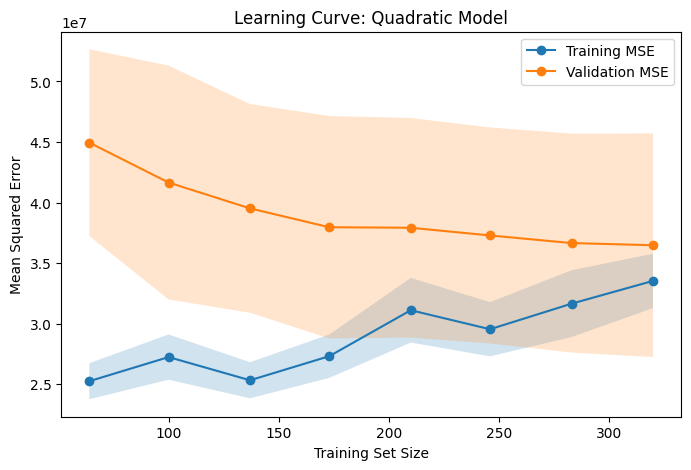

In [52]:
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge

# Use the selected Quadratic model from Phase 3
model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    Ridge(alpha=1.0)
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

sizes, train_scores, val_scores = learning_curve(
    model,
    X[main_cols],
    y,
    train_sizes=np.linspace(0.2, 1.0, 8),
    cv=cv,
    scoring="neg_mean_squared_error"
)

train_mse = -train_scores
val_mse = -val_scores

train_mean = train_mse.mean(axis=1)
val_mean = val_mse.mean(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(sizes, train_mean, marker="o", label="Training MSE")
plt.plot(sizes, val_mean, marker="o", label="Validation MSE")

plt.fill_between(
    sizes,
    train_mean - train_mse.std(axis=1),
    train_mean + train_mse.std(axis=1),
    alpha=0.2
)

plt.fill_between(
    sizes,
    val_mean - val_mse.std(axis=1),
    val_mean + val_mse.std(axis=1),
    alpha=0.2
)

plt.xlabel("Training Set Size")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve: Quadratic Model")
plt.legend()
plt.show()

# A large gap suggests high variance: more data may help.
# High errors with a small gap suggest high bias: better features may help.


The learning curve shows that the gap between training and validation MSE becomes smaller as the training size increases. This suggests that more data helps reduce variance.

However, both curves begin to level off, with training MSE at around 34 million and validation MSE at around 39 million. This suggests that adding more stores may offer limited additional benefits.

This agrees with Phase 3, where the Quadratic model performed better than simpler models, but added complexity did not improve validation performance. I would prioritize improving the features and model specification rather than simply collecting more stores.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [53]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.95


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=8. All the features will be returned.
  warnings.warn(


SelectKBest causes data leakage because it uses the full dataset, including the validation data, to select features before cross-validation. This can make the reported R² too optimistic.

StandardScaler does not inflate the score because OLS with an intercept can adjust its coefficients when features are rescaled, so the predictions remain unchanged.

In [54]:
from sklearn.pipeline import Pipeline
import numpy as np

# Create 300 noise features
rng = np.random.default_rng(42)
X_noise = rng.normal(size=(len(y), 300))

# Original method
X_scaled = StandardScaler().fit_transform(X_noise)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")

print(f"Original R^2: {scores.mean():.2f}")

# Pipeline method
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(f_regression, k=20)),
    ("model", LinearRegression())])

scores_pipe = cross_val_score(pipe, X_noise, y, cv=5, scoring="r2")

print(f"Pipeline R^2: {scores_pipe.mean():.2f}")
print(f"Gap: {scores.mean() - scores_pipe.mean():.2f}")

Original R^2: 0.13
Pipeline R^2: -0.28
Gap: 0.41


This is a special case of the same general problem because feature selection uses validation data before cross-validation, making the reported performance too optimistic.

### Task 4.3: The handover note (3 pts)

The model predicts revenue for individual stores using store characteristics such as floor area, foot traffic, local income, and years open.

I selected a quadratic model through 5-fold cross-validation. Its held-out MSE was about 48.84 million dollars squared, with a 95% confidence interval of 29.06 to 68.62 million dollars squared. However, since I also examined this test set during model development, the estimate may still be optimistic.

One possible problem is predicting revenue for very large stores. The original linear model over-forecast revenue for the largest stores by about $7,100 on average, suggesting that store size can influence prediction errors. Another concern is that revenue patterns may change over time, which the simulated data do not capture.

Next, I would collect data across multiple months, improve the nonlinear features, and evaluate the final model on completely new data before using it to make business decisions.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:* ChatGPT Nov 18,2026

*Prompt:*

[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.

*Reply:*


from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge

# Use the selected Quadratic model from Phase 3
model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    Ridge(alpha=1.0)
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

sizes, train_scores, val_scores = learning_curve(
    model,
    X[main_cols],
    y,
    train_sizes=np.linspace(0.2, 1.0, 8),
    cv=cv,
    scoring="neg_mean_squared_error"
)

train_mse = -train_scores
val_mse = -val_scores

train_mean = train_mse.mean(axis=1)
val_mean = val_mse.mean(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(sizes, train_mean, marker="o", label="Training MSE")
plt.plot(sizes, val_mean, marker="o", label="Validation MSE")

plt.fill_between(
    sizes,
    train_mean - train_mse.std(axis=1),
    train_mean + train_mse.std(axis=1),
    alpha=0.2
)

plt.fill_between(
    sizes,
    val_mean - val_mse.std(axis=1),
    val_mean + val_mse.std(axis=1),
    alpha=0.2
)

plt.xlabel("Training Set Size")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve: Quadratic Model")
plt.legend()
plt.show()

# A large gap suggests high variance: more data may help.
# High errors with a small gap suggest high bias: better features may help.


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.